In [1]:
from google.colab import files

uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


# Initial Data Understanding


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

In [3]:
# Missing values
print("Missing values:")
print(df.isnull().sum().sum())

# Duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Target distribution
print("\nFraud distribution:")
print(df["Class"].value_counts())

# Fraud percentage
print("\nFraud percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

# Descriptive statistics
display(df.describe().T)

Missing values:
0

Duplicate rows:
1081

Fraud distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [4]:

duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:",
      len(duplicate_rows))

print("\nDuplicate records by class:")
print(duplicate_rows["Class"].value_counts())

print("\nDuplicate records by class (%):")
print(duplicate_rows["Class"].value_counts(normalize=True) * 100)

# Duplicates excluding the first occurrence
duplicate_excess = df[df.duplicated(keep="first")]

print("\nRepeated rows excluding first occurrence:")
print(len(duplicate_excess))

print("\nRepeated rows by class:")
print(duplicate_excess["Class"].value_counts())

Rows involved in duplicate groups: 1854

Duplicate records by class:
Class
0    1822
1      32
Name: count, dtype: int64

Duplicate records by class (%):
Class
0    98.274002
1     1.725998
Name: proportion, dtype: float64

Repeated rows excluding first occurrence:
1081

Repeated rows by class:
Class
0    1062
1      19
Name: count, dtype: int64


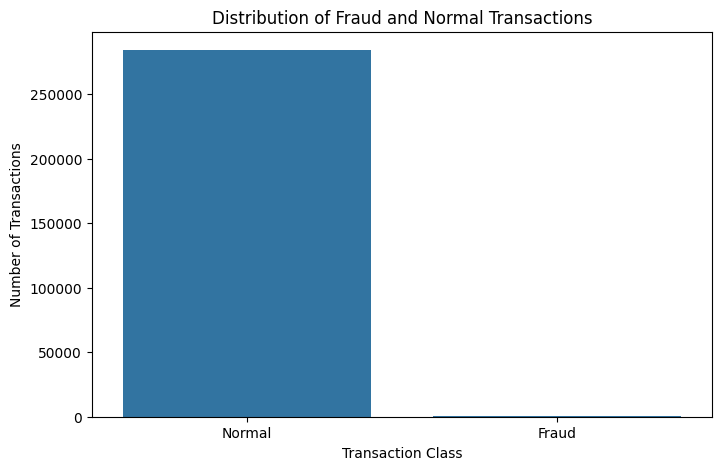

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Class")

plt.title("Distribution of Fraud and Normal Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()


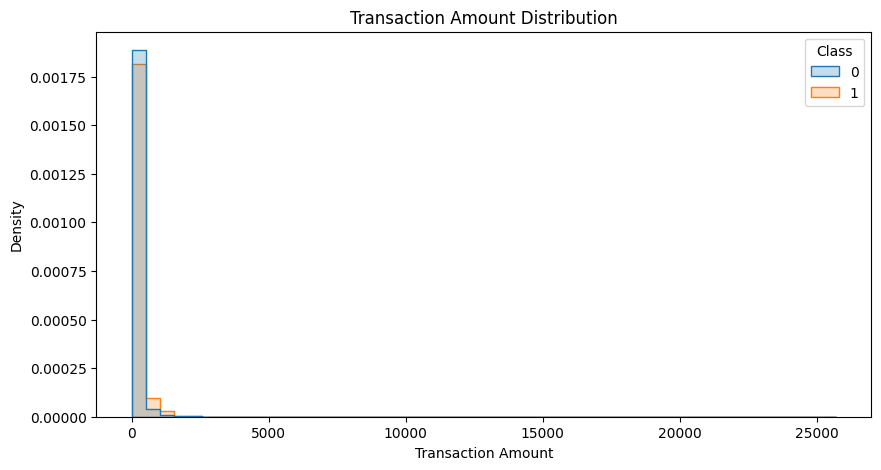

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.show()


In [7]:
amount_comparison = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(amount_comparison)

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.291022,22.00,250.105092,0.0,25691.16
1,492,122.211321,9.25,256.683288,0.0,2125.87


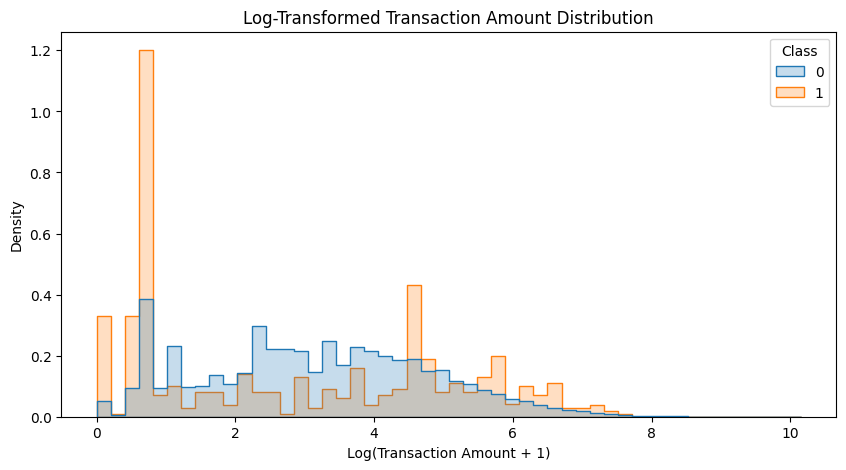

In [8]:
df["Log_Amount"] = np.log1p(df["Amount"])

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Log_Amount",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("Log(Transaction Amount + 1)")
plt.ylabel("Density")

plt.show()

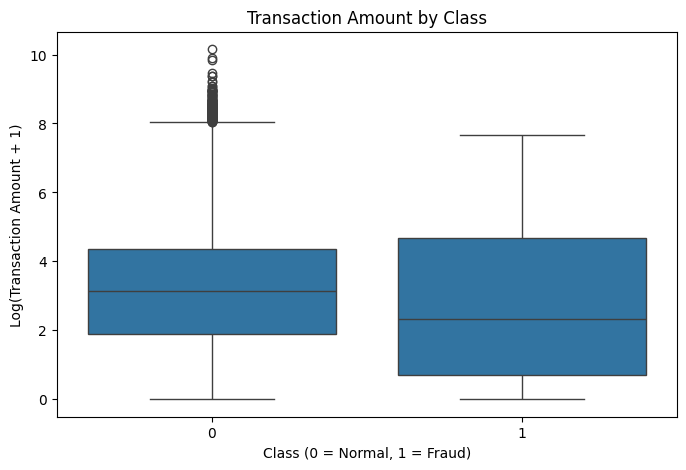

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Log_Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Log(Transaction Amount + 1)")

plt.show()

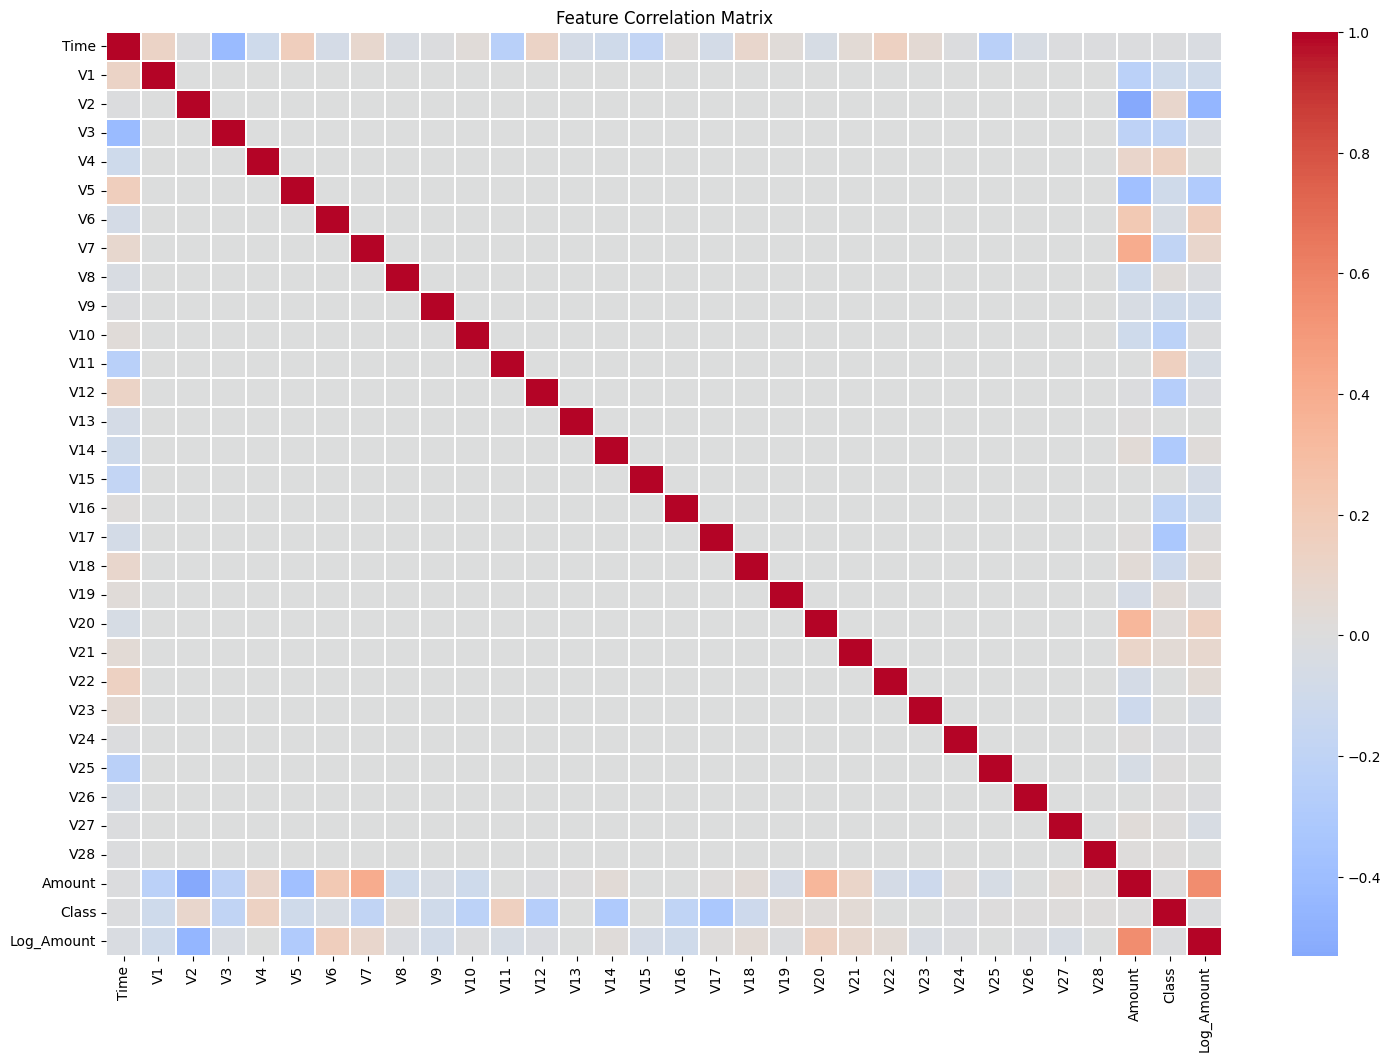

In [10]:
plt.figure(figsize=(18, 12))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Matrix")
plt.show()

In [11]:
fraud_corr = df.corr()["Class"].drop("Class")

fraud_corr = fraud_corr.sort_values(
    key=abs,
    ascending=False
)

display(fraud_corr.head(15))

,Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V11,0.154876
V4,0.133447
V18,-0.111485


In [12]:
# Correlation between independent features
feature_corr = df.drop(columns=["Class"]).corr()

# Get upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

# Find highly correlated feature pairs
high_corr = (
    upper_triangle.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr["Abs_Correlation"] = high_corr["Correlation"].abs()

high_corr = high_corr.sort_values(
    "Abs_Correlation",
    ascending=False
)

display(high_corr.head(15))

,Feature 1,Feature 2,Correlation,Abs_Correlation
464,Amount,Log_Amount,0.552005,0.552005
85,V2,Amount,-0.531409,0.531409
86,V2,Log_Amount,-0.450317,0.450317
2,Time,V3,-0.419618,0.419618
210,V7,Amount,0.397311,0.397311
163,V5,Amount,-0.386356,0.386356
418,V20,Amount,0.339403,0.339403
164,V5,Log_Amount,-0.286189,0.286189
10,Time,V11,-0.247689,0.247689
24,Time,V25,-0.233083,0.233083


In [13]:
feature_corr = df.drop(columns=["Class"]).corr()

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle.stack()
    .reset_index()
)

high_corr.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr["Abs_Correlation"] = high_corr["Correlation"].abs()

high_corr = high_corr.sort_values(
    "Abs_Correlation",
    ascending=False
).reset_index(drop=True)

display(high_corr.head(15))

,Feature 1,Feature 2,Correlation,Abs_Correlation
0,Amount,Log_Amount,0.552005,0.552005
1,V2,Amount,-0.531409,0.531409
2,V2,Log_Amount,-0.450317,0.450317
3,Time,V3,-0.419618,0.419618
4,V7,Amount,0.397311,0.397311
5,V5,Amount,-0.386356,0.386356
6,V20,Amount,0.339403,0.339403
7,V5,Log_Amount,-0.286189,0.286189
8,Time,V11,-0.247689,0.247689
9,Time,V25,-0.233083,0.233083


In [14]:
df_model = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("After removing duplicates:", df_model.shape)

print("\nClass distribution:")
print(df_model["Class"].value_counts())

Original dataset: (284807, 32)
After removing duplicates: (283726, 32)

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [15]:
X = df_model.drop(columns=["Class", "Log_Amount"])
y = df_model["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [16]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["Class", "Log_Amount"])
y = df_model["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training set: (226980, 30)
Testing set: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64
Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64
Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

log_reg_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [18]:
y_pred = log_reg_model.predict(X_test)

y_pred_proba = log_reg_model.predict_proba(X_test)[:, 1]

In [19]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))

print("PR-AUC:", average_precision_score(y_test, y_pred_proba))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

Confusion Matrix:
[[55262  1389]
 [   12    83]]
ROC-AUC: 0.9656548079701293
PR-AUC: 0.6719244530518994


In [20]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Subtrain:", X_subtrain.shape)
print("Validation:", X_val.shape)

Subtrain: (181584, 30)
Validation: (45396, 30)


In [21]:
threshold_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

threshold_model.fit(X_subtrain, y_subtrain)

val_proba = threshold_model.predict_proba(X_val)[:, 1]

In [22]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.05):

    val_pred = (val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, val_pred),
        "Recall": recall_score(y_val, val_pred),
        "F1-score": f1_score(y_val, val_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score
0,0.05,0.0056,0.9605,0.0111
1,0.10,0.0096,0.9474,0.0190
2,0.15,0.0138,0.9474,0.0272
3,0.20,0.0178,0.9211,0.0349
4,0.25,0.0218,0.9079,0.0426
5,0.30,0.0269,0.9079,0.0523
6,0.35,0.0333,0.9079,0.0642
7,0.40,0.0394,0.9079,0.0755
8,0.45,0.0464,0.9079,0.0883
9,0.50,0.0542,0.8947,0.1023


In [23]:
threshold_results = []

for threshold in np.arange(0.90, 1.00, 0.01):

    val_pred = (val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1-score": f1_score(y_val, val_pred, zero_division=0)
    })

threshold_df_fine = pd.DataFrame(threshold_results)

display(threshold_df_fine.round(4))

,Threshold,Precision,Recall,F1-score
0,0.90,0.2391,0.8684,0.3750
1,0.91,0.2588,0.8684,0.3988
2,0.92,0.2833,0.8684,0.4272
3,0.93,0.3099,0.8684,0.4567
4,0.94,0.3300,0.8684,0.4783
5,0.95,0.3667,0.8684,0.5156
6,0.96,0.4099,0.8684,0.5570
7,0.97,0.4748,0.8684,0.6140
8,0.98,0.5366,0.8684,0.6633
9,0.99,0.5752,0.8553,0.6878


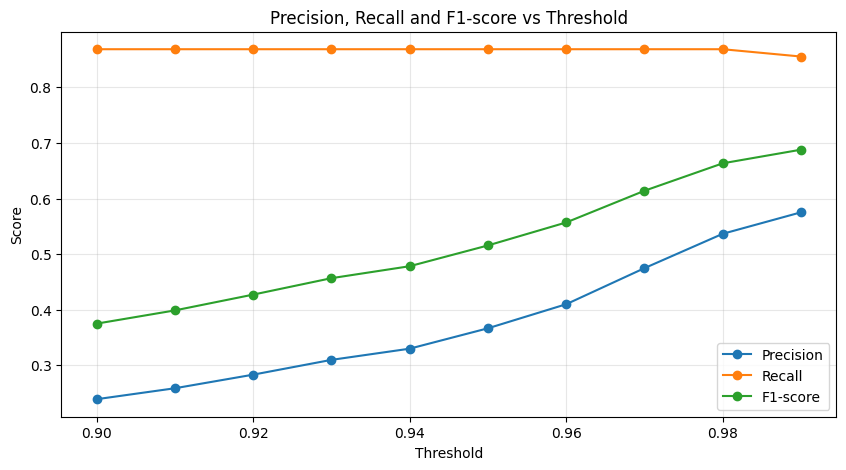

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df_fine["Threshold"],
    threshold_df_fine["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df_fine["Threshold"],
    threshold_df_fine["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df_fine["Threshold"],
    threshold_df_fine["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-score vs Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
from sklearn.metrics import confusion_matrix, classification_report

best_threshold = 0.95

val_pred_095 = (val_proba >= best_threshold).astype(int)

print(confusion_matrix(y_val, val_pred_095))
print(classification_report(y_val, val_pred_095))

[[45206   114]
 [   10    66]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.37      0.87      0.52        76

    accuracy                           1.00     45396
   macro avg       0.68      0.93      0.76     45396
weighted avg       1.00      1.00      1.00     45396



In [26]:
print("Fraud count:", y_val.sum())
print("Predicted fraud:", val_pred.sum())

print("Precision:", precision_score(y_val, val_pred))
print("Recall:", recall_score(y_val, val_pred))
print("F1:", f1_score(y_val, val_pred))

Fraud count: 76
Predicted fraud: 113
Precision: 0.5752212389380531
Recall: 0.8552631578947368
F1: 0.6878306878306878


In [27]:
test_proba = threshold_model.predict_proba(X_test)[:, 1]

best_threshold = 0.99
test_pred = (test_proba >= best_threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

print("ROC-AUC:", roc_auc_score(y_test, test_proba))
print("PR-AUC:", average_precision_score(y_test, test_proba))

Confusion Matrix:
[[56605    46]
 [   20    75]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.62      0.79      0.69        95

    accuracy                           1.00     56746
   macro avg       0.81      0.89      0.85     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9616843294446421
PR-AUC: 0.6870645749940067


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

In [29]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [30]:
rf_model.fit(X_subtrain, y_subtrain)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [31]:
rf_val_proba = rf_model.predict_proba(X_val)[:, 1]

In [32]:
rf_val_pred = (rf_val_proba >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, rf_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, rf_val_pred))

print("ROC-AUC:", roc_auc_score(y_val, rf_val_proba))
print("PR-AUC:", average_precision_score(y_val, rf_val_proba))

Confusion Matrix:
[[45318     2]
 [   15    61]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.97      0.80      0.88        76

    accuracy                           1.00     45396
   macro avg       0.98      0.90      0.94     45396
weighted avg       1.00      1.00      1.00     45396

ROC-AUC: 0.9456818762484323
PR-AUC: 0.877041475254237


In [33]:
threshold_results_rf = []

for threshold in np.arange(0.05, 1.00, 0.05):

    rf_pred = (rf_val_proba >= threshold).astype(int)

    threshold_results_rf.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, rf_pred, zero_division=0),
        "Recall": recall_score(y_val, rf_pred, zero_division=0),
        "F1-score": f1_score(y_val, rf_pred, zero_division=0)
    })

threshold_df_rf = pd.DataFrame(threshold_results_rf)

display(threshold_df_rf.round(4))

,Threshold,Precision,Recall,F1-score
0,0.05,0.7204,0.8816,0.7929
1,0.10,0.8462,0.8684,0.8571
2,0.15,0.9041,0.8684,0.8859
3,0.20,0.9286,0.8553,0.8904
4,0.25,0.9420,0.8553,0.8966
5,0.30,0.9420,0.8553,0.8966
6,0.35,0.9552,0.8421,0.8951
7,0.40,0.9697,0.8421,0.9014
8,0.45,0.9692,0.8289,0.8936
9,0.50,0.9683,0.8026,0.8777


In [34]:
threshold_results_rf_fine = []

for threshold in np.arange(0.35, 0.451, 0.01):

    rf_pred = (rf_val_proba >= threshold).astype(int)

    threshold_results_rf_fine.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, rf_pred, zero_division=0),
        "Recall": recall_score(y_val, rf_pred, zero_division=0),
        "F1-score": f1_score(y_val, rf_pred, zero_division=0)
    })

threshold_df_rf_fine = pd.DataFrame(threshold_results_rf_fine)

display(threshold_df_rf_fine.round(4))

,Threshold,Precision,Recall,F1-score
0,0.35,0.9552,0.8421,0.8951
1,0.36,0.9552,0.8421,0.8951
2,0.37,0.9552,0.8421,0.8951
3,0.38,0.9552,0.8421,0.8951
4,0.39,0.9552,0.8421,0.8951
5,0.40,0.9697,0.8421,0.9014
6,0.41,0.9692,0.8289,0.8936
7,0.42,0.9692,0.8289,0.8936
8,0.43,0.9692,0.8289,0.8936
9,0.44,0.9692,0.8289,0.8936


In [35]:
# Test dataset üzrə fraud ehtimalları
rf_test_proba = rf_model.predict_proba(X_test)[:, 1]

# Validation-da seçdiyimiz threshold
best_threshold_rf = 0.40

# Final predictions
rf_test_pred = (rf_test_proba >= best_threshold_rf).astype(int)

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, rf_test_pred))

# ROC-AUC
print("ROC-AUC:", roc_auc_score(y_test, rf_test_proba))

# PR-AUC
print("PR-AUC:", average_precision_score(y_test, rf_test_proba))

Confusion Matrix:
[[56648     3]
 [   27    68]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9445989247181962
PR-AUC: 0.8075891502221076


In [36]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)
import pandas as pd

# Logistic Regression — test predictions
lr_test_proba = threshold_model.predict_proba(X_test)[:, 1]
lr_test_pred = (lr_test_proba >= 0.99).astype(int)

# Random Forest — test predictions
rf_test_proba = rf_model.predict_proba(X_test)[:, 1]
rf_test_pred = (rf_test_proba >= 0.40).astype(int)

# Müqayisə cədvəli
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Threshold": [0.99, 0.40],
    "Precision": [
        precision_score(y_test, lr_test_pred),
        precision_score(y_test, rf_test_pred)
    ],
    "Recall": [
        recall_score(y_test, lr_test_pred),
        recall_score(y_test, rf_test_pred)
    ],
    "F1-score": [
        f1_score(y_test, lr_test_pred),
        f1_score(y_test, rf_test_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_test_proba),
        roc_auc_score(y_test, rf_test_proba)
    ],
    "PR-AUC": [
        average_precision_score(y_test, lr_test_proba),
        average_precision_score(y_test, rf_test_proba)
    ]
})

display(comparison.round(4))

,Model,Threshold,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.99,0.6198,0.7895,0.6944,0.9617,0.6871
1,Random Forest,0.40,0.9577,0.7158,0.8193,0.9446,0.8076


In [37]:
!pip install xgboost

In [38]:
from xgboost import XGBClassifier

# Siniflərin nisbəti
negative_count = (y_subtrain == 0).sum()
positive_count = (y_subtrain == 1).sum()

scale_weight = negative_count / positive_count

print("Scale pos weight:", scale_weight)

# XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)


xgb_model.fit(X_subtrain, y_subtrain)


xgb_val_proba = xgb_model.predict_proba(X_val)[:, 1]


xgb_val_pred = (xgb_val_proba >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, xgb_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, xgb_val_pred))

print("ROC-AUC:", roc_auc_score(y_val, xgb_val_proba))
print("PR-AUC:", average_precision_score(y_val, xgb_val_proba))

Scale pos weight: 600.2715231788079
Confusion Matrix:
[[45300    20]
 [    9    67]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.77      0.88      0.82        76

    accuracy                           1.00     45396
   macro avg       0.88      0.94      0.91     45396
weighted avg       1.00      1.00      1.00     45396

ROC-AUC: 0.9755646978213406
PR-AUC: 0.8757094821066665


In [39]:
threshold_results_xgb = []

for threshold in np.arange(0.05, 1.00, 0.05):
    xgb_pred = (xgb_val_proba >= threshold).astype(int)

    threshold_results_xgb.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, xgb_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, xgb_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, xgb_pred, zero_division=0
        )
    })

threshold_df_xgb = pd.DataFrame(threshold_results_xgb)

display(threshold_df_xgb.round(4))

,Threshold,Precision,Recall,F1-score
0,0.05,0.1658,0.8816,0.2792
1,0.10,0.2691,0.8816,0.4123
2,0.15,0.3722,0.8816,0.5234
3,0.20,0.4685,0.8816,0.6119
4,0.25,0.5234,0.8816,0.6569
5,0.30,0.5678,0.8816,0.6907
6,0.35,0.6262,0.8816,0.7322
7,0.40,0.7128,0.8816,0.7882
8,0.45,0.7444,0.8816,0.8072
9,0.50,0.7701,0.8816,0.8221


In [40]:
threshold_results_xgb_fine = []

for threshold in np.arange(0.80, 0.921, 0.01):
    xgb_pred = (xgb_val_proba >= threshold).astype(int)

    threshold_results_xgb_fine.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, xgb_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, xgb_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, xgb_pred, zero_division=0
        )
    })

threshold_df_xgb_fine = pd.DataFrame(threshold_results_xgb_fine)

display(threshold_df_xgb_fine.round(4))

,Threshold,Precision,Recall,F1-score
0,0.80,0.9028,0.8553,0.8784
1,0.81,0.9028,0.8553,0.8784
2,0.82,0.9028,0.8553,0.8784
3,0.83,0.9028,0.8553,0.8784
4,0.84,0.9155,0.8553,0.8844
5,0.85,0.9155,0.8553,0.8844
6,0.86,0.9155,0.8553,0.8844
7,0.87,0.9155,0.8553,0.8844
8,0.88,0.9155,0.8553,0.8844
9,0.89,0.9155,0.8553,0.8844


In [41]:
best_threshold_xgb = 0.84

xgb_val_pred_best = (
    xgb_val_proba >= best_threshold_xgb
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, xgb_val_pred_best))

print("\nClassification Report:")
print(classification_report(y_val, xgb_val_pred_best))

Confusion Matrix:
[[45314     6]
 [   11    65]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.92      0.86      0.88        76

    accuracy                           1.00     45396
   macro avg       0.96      0.93      0.94     45396
weighted avg       1.00      1.00      1.00     45396



In [42]:

xgb_test_proba = xgb_model.predict_proba(X_test)[:, 1]

xgb_test_pred = (
    xgb_test_proba >= best_threshold_xgb
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, xgb_test_pred))

print("ROC-AUC:", roc_auc_score(y_test, xgb_test_proba))
print("PR-AUC:", average_precision_score(y_test, xgb_test_proba))

Confusion Matrix:
[[56642     9]
 [   21    74]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.89      0.78      0.83        95

    accuracy                           1.00     56746
   macro avg       0.95      0.89      0.92     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9687677738768024
PR-AUC: 0.8171235397053419


,Feature,Importance
14,V14,0.372568
10,V10,0.084614
4,V4,0.063537
8,V8,0.046367
12,V12,0.042319
20,V20,0.032071
3,V3,0.030646
19,V19,0.030284
29,Amount,0.022204
21,V21,0.022120


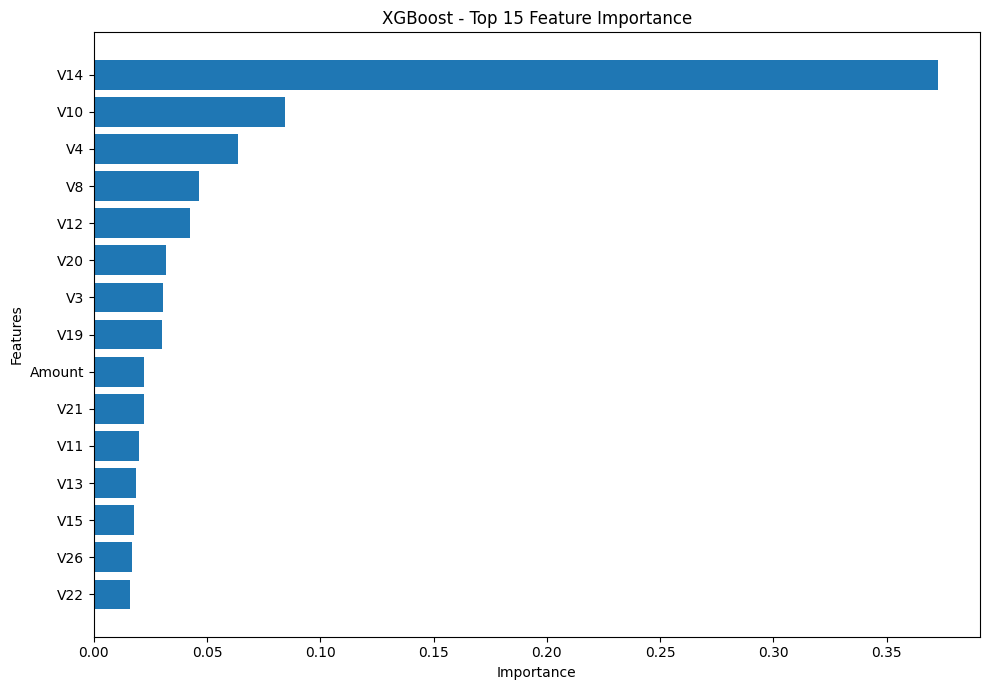

In [43]:
import pandas as pd
import matplotlib.pyplot as plt


feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})


feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# İlk 15 feature
display(feature_importance.head(15))

# Vizualizasiya
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance.head(15)["Feature"][::-1],
    feature_importance.head(15)["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("XGBoost - Top 15 Feature Importance")
plt.tight_layout()
plt.show()

In [44]:
!pip install shap

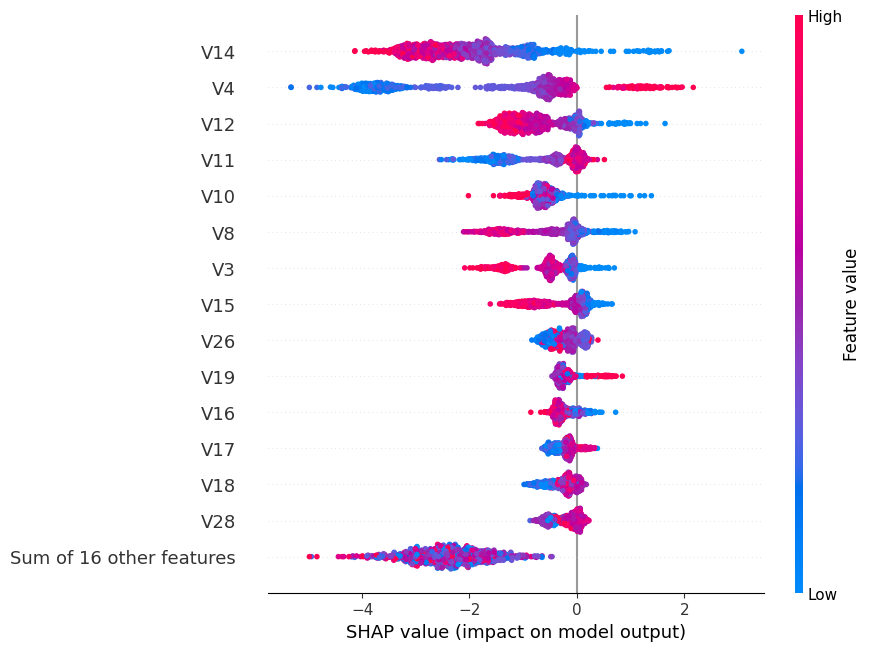

In [45]:
import shap


explainer = shap.TreeExplainer(xgb_model)


X_sample = X_test.sample(
    n=1000,
    random_state=42
)


shap_values = explainer(X_sample)


shap.plots.beeswarm(shap_values, max_display=15)

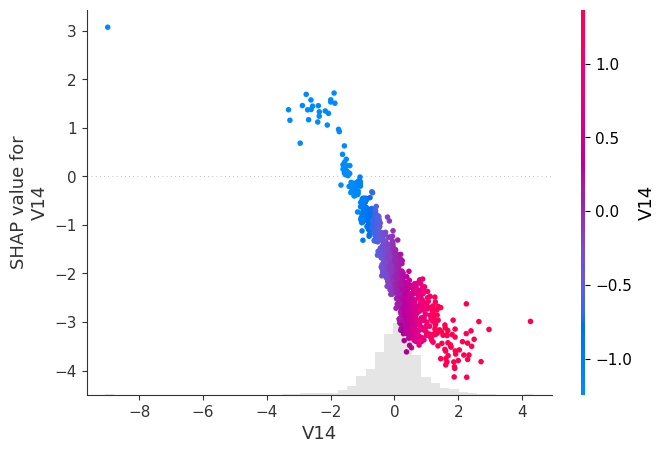

In [46]:

shap.plots.scatter(
    shap_values[:, "V14"],
    color=shap_values[:, "V14"]
)

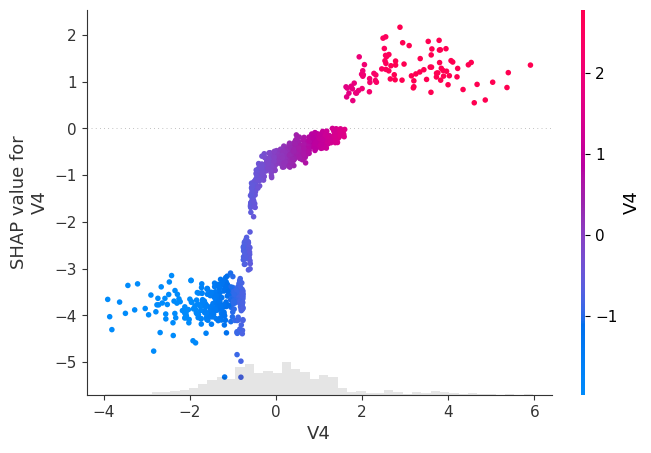

In [47]:
shap.plots.scatter(
    shap_values[:, "V4"],
    color=shap_values[:, "V4"]
)

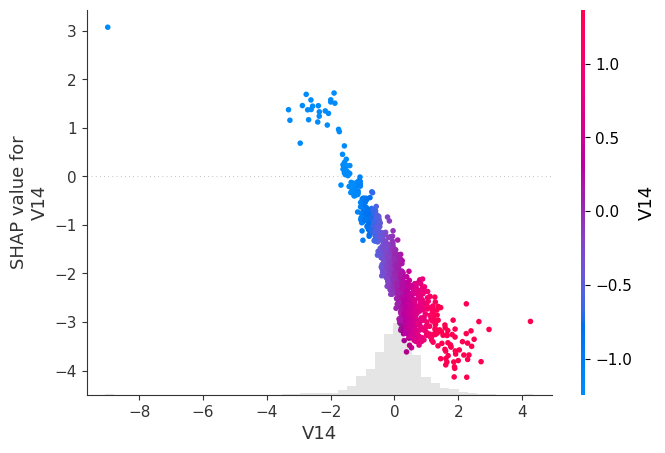

In [48]:
shap.plots.scatter(
    shap_values[:, "V14"],
    color=shap_values[:, "V14"]
)

Brier Score: 0.0007852668058327256


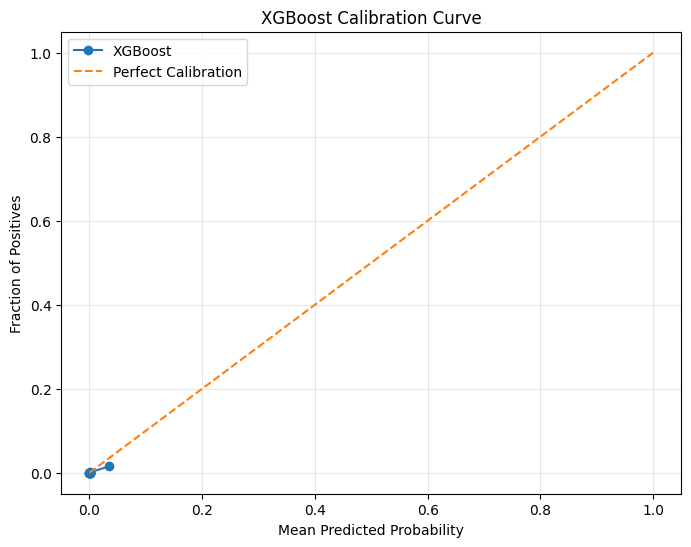

In [49]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Test dataset üzrə ehtimallar
xgb_test_proba = xgb_model.predict_proba(X_test)[:, 1]

# Calibration curve
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test,
    xgb_test_proba,
    n_bins=10,
    strategy="quantile"
)

# Brier Score
brier = brier_score_loss(y_test, xgb_test_proba)

print("Brier Score:", brier)

# Visualization
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("XGBoost Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [50]:
import numpy as np
import pandas as pd

print("Brier Score:", brier_score_loss(y_test, xgb_test_proba))
print("Actual Fraud Rate:", y_test.mean())
print("Minimum Probability:", xgb_test_proba.min())
print("Maximum Probability:", xgb_test_proba.max())

print("\nProbability Quantiles:")
print(pd.Series(xgb_test_proba).quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1]
))

print("\nNumber of unique probability values:",
      len(np.unique(xgb_test_proba)))

Brier Score: 0.0007852668058327256
Actual Fraud Rate: 0.0016741268107003137
Minimum Probability: 1.3742639e-06
Maximum Probability: 0.9999398

Probability Quantiles:
0.000    0.000001
0.250    0.000053
0.500    0.000161
0.750    0.000560
0.900    0.002157
0.950    0.005897
0.990    0.043611
0.999    0.999229
1.000    0.999940
dtype: float64

Number of unique probability values: 55560


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from scipy.special import logit
import numpy as np

# Validation və test ehtimalları
xgb_val_proba = xgb_model.predict_proba(X_val)[:, 1]
xgb_test_proba = xgb_model.predict_proba(X_test)[:, 1]

# Ehtimalların 0 və 1 olmasının qarşısını alırıq
eps = 1e-6

val_proba_clipped = np.clip(xgb_val_proba, eps, 1 - eps)
test_proba_clipped = np.clip(xgb_test_proba, eps, 1 - eps)

# Platt Scaling
val_logits = logit(val_proba_clipped).reshape(-1, 1)
test_logits = logit(test_proba_clipped).reshape(-1, 1)

platt_model = LogisticRegression()
platt_model.fit(val_logits, y_val)

platt_test_proba = platt_model.predict_proba(
    test_logits
)[:, 1]

# Isotonic Regression
isotonic_model = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

isotonic_model.fit(xgb_val_proba, y_val)

isotonic_test_proba = isotonic_model.predict(
    xgb_test_proba
)

print("Calibration models trained successfully.")

Calibration models trained successfully.


In [52]:
from sklearn.metrics import brier_score_loss

calibration_results = pd.DataFrame({
    "Model": [
        "Original XGBoost",
        "Platt Scaling",
        "Isotonic Regression"
    ],
    "Brier Score": [
        brier_score_loss(y_test, xgb_test_proba),
        brier_score_loss(y_test, platt_test_proba),
        brier_score_loss(y_test, isotonic_test_proba)
    ]
})

display(calibration_results.round(6))

,Model,Brier Score
0,Original XGBoost,0.000785
1,Platt Scaling,0.000454
2,Isotonic Regression,0.000448


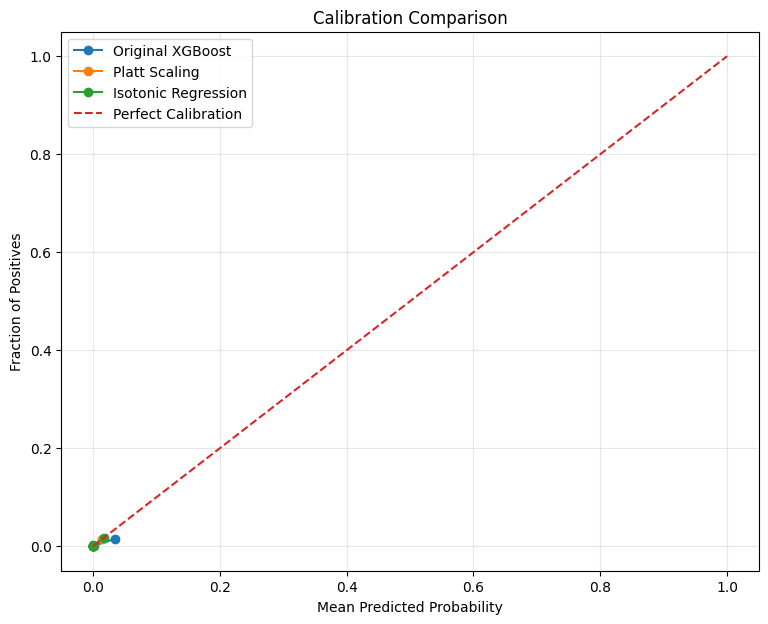

In [53]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

models_proba = {
    "Original XGBoost": xgb_test_proba,
    "Platt Scaling": platt_test_proba,
    "Isotonic Regression": isotonic_test_proba
}

plt.figure(figsize=(9, 7))

for name, probabilities in models_proba.items():

    fraction_positive, mean_predicted = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [54]:
from sklearn.calibration import calibration_curve
import numpy as np

def calculate_ece(y_true, y_prob, n_bins=10):

    fraction_positive, mean_predicted = calibration_curve(
        y_true,
        y_prob,
        n_bins=n_bins,
        strategy="quantile"
    )

    bin_counts = np.histogram(
        y_prob,
        bins=n_bins
    )[0]

    # Quantile bölgülərinin çəkiləri
    weights = np.ones(len(mean_predicted)) / len(mean_predicted)

    ece = np.sum(
        weights * np.abs(fraction_positive - mean_predicted)
    )

    return ece


for name, probabilities in models_proba.items():
    print(
        name,
        "ECE:",
        calculate_ece(y_test, probabilities)
    )

Original XGBoost ECE: 0.0020787330985595947
Platt Scaling ECE: 0.000262629655719293
Isotonic Regression ECE: 0.0003464587914413007


In [55]:
def calculate_ece(y_true, y_prob, n_bins=10):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.quantile(
        y_prob,
        np.linspace(0, 1, n_bins + 1)
    )

    bin_edges = np.unique(bin_edges)

    ece = 0

    for i in range(len(bin_edges) - 1):

        if i == len(bin_edges) - 2:
            mask = (
                (y_prob >= bin_edges[i]) &
                (y_prob <= bin_edges[i + 1])
            )
        else:
            mask = (
                (y_prob >= bin_edges[i]) &
                (y_prob < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        avg_confidence = y_prob[mask].mean()
        avg_accuracy = y_true[mask].mean()

        bin_weight = mask.sum() / len(y_true)

        ece += bin_weight * abs(
            avg_accuracy - avg_confidence
        )

    return ece


for name, probabilities in models_proba.items():

    print(
        name,
        "ECE:",
        calculate_ece(y_test, probabilities)
    )

Original XGBoost ECE: 0.0020788616300553343
Platt Scaling ECE: 0.00026262524044179825
Isotonic Regression ECE: 0.00015717046267675294


In [56]:
# Dataset-i Time sütununa görə sıralayırıq
df_time = df_model.sort_values(
    by="Time"
).reset_index(drop=True)

# 60% / 20% / 20% bölgüsü
n = len(df_time)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_time = df_time.iloc[:train_end].copy()
val_time = df_time.iloc[train_end:val_end].copy()
test_time = df_time.iloc[val_end:].copy()

# Feature və target
X_train_time = train_time.drop(
    columns=["Class", "Log_Amount"],
    errors="ignore"
)
y_train_time = train_time["Class"]

X_val_time = val_time.drop(
    columns=["Class", "Log_Amount"],
    errors="ignore"
)
y_val_time = val_time["Class"]

X_test_time = test_time.drop(
    columns=["Class", "Log_Amount"],
    errors="ignore"
)
y_test_time = test_time["Class"]

In [57]:
time_splits = {
    "Train": train_time,
    "Validation": val_time,
    "Test": test_time
}

for name, data in time_splits.items():

    print(f"\n{name}")
    print("-" * 35)

    print("Rows:", len(data))
    print("Time range:",
          data["Time"].min(),
          "to",
          data["Time"].max())

    print("Normal transactions:",
          (data["Class"] == 0).sum())

    print("Fraud transactions:",
          (data["Class"] == 1).sum())

    print("Fraud rate:",
          round(data["Class"].mean() * 100, 4), "%")


Train
-----------------------------------
Rows: 170235
Time range: 0.0 to 120392.0
Normal transactions: 169893
Fraud transactions: 342
Fraud rate: 0.2009 %

Validation
-----------------------------------
Rows: 56745
Time range: 120393.0 to 145233.0
Normal transactions: 56688
Fraud transactions: 57
Fraud rate: 0.1004 %

Test
-----------------------------------
Rows: 56746
Time range: 145234.0 to 172792.0
Normal transactions: 56672
Fraud transactions: 74
Fraud rate: 0.1304 %


In [58]:
from xgboost import XGBClassifier

# Sinif balansı üçün scale_pos_weight
scale_pos_weight_time = (
    (y_train_time == 0).sum() /
    (y_train_time == 1).sum()
)

print("Scale Pos Weight:", scale_pos_weight_time)

# XGBoost model
xgb_time_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_time,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

# Modelin öyrədilməsi
xgb_time_model.fit(
    X_train_time,
    y_train_time
)

print("Time-based XGBoost trained successfully!")

Scale Pos Weight: 496.7631578947368
Time-based XGBoost trained successfully!


In [59]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Validation ehtimalları
xgb_time_val_proba = xgb_time_model.predict_proba(
    X_val_time
)[:, 1]

# İlkin threshold: 0.5
xgb_time_val_pred = (
    xgb_time_val_proba >= 0.5
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val_time, xgb_time_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val_time,
    xgb_time_val_pred,
    zero_division=0
))

print("ROC-AUC:",
      roc_auc_score(y_val_time, xgb_time_val_proba))

print("PR-AUC:",
      average_precision_score(y_val_time, xgb_time_val_proba))

Confusion Matrix:
[[56676    12]
 [   14    43]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56688
           1       0.78      0.75      0.77        57

    accuracy                           1.00     56745
   macro avg       0.89      0.88      0.88     56745
weighted avg       1.00      1.00      1.00     56745

ROC-AUC: 0.9773317537422445
PR-AUC: 0.7866484198083203


In [60]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

thresholds = np.arange(0.10, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:
    y_pred = (xgb_time_val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val_time, y_pred),
        "Recall": recall_score(y_val_time, y_pred),
        "F1-Score": f1_score(y_val_time, y_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

    Threshold  Precision  Recall  F1-Score
0        0.10     0.3760  0.8246    0.5165
1        0.15     0.4742  0.8070    0.5974
2        0.20     0.5116  0.7719    0.6154
3        0.25     0.5641  0.7719    0.6519
4        0.30     0.6286  0.7719    0.6929
5        0.35     0.6567  0.7719    0.7097
6        0.40     0.7213  0.7719    0.7458
7        0.45     0.7586  0.7719    0.7652
8        0.50     0.7818  0.7544    0.7679
9        0.55     0.7963  0.7544    0.7748
10       0.60     0.8113  0.7544    0.7818
11       0.65     0.8113  0.7544    0.7818
12       0.70     0.8113  0.7544    0.7818
13       0.75     0.8431  0.7544    0.7963
14       0.80     0.8776  0.7544    0.8113
15       0.85     0.9130  0.7368    0.8155
16       0.90     0.9318  0.7193    0.8119
17       0.95     0.9302  0.7018    0.8000


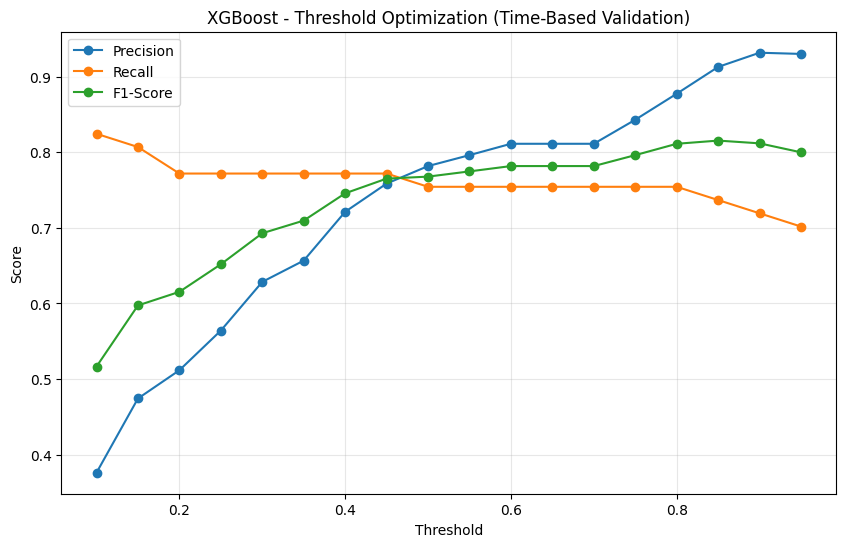

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("XGBoost - Threshold Optimization (Time-Based Validation)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [62]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

print("Best Threshold:")
print(best_threshold_row)

Best Threshold:
Threshold    0.850000
Precision    0.913043
Recall       0.736842
F1-Score     0.815534
Name: 15, dtype: float64


In [63]:
best_threshold = best_threshold_row["Threshold"]

y_val_pred_best = (
    xgb_time_val_proba >= best_threshold
).astype(int)

print("Selected Threshold:", best_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_time, y_val_pred_best))

print("\nClassification Report:")
print(classification_report(y_val_time, y_val_pred_best))

Selected Threshold: 0.85

Confusion Matrix:
[[56684     4]
 [   15    42]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56688
           1       0.91      0.74      0.82        57

    accuracy                           1.00     56745
   macro avg       0.96      0.87      0.91     56745
weighted avg       1.00      1.00      1.00     56745



In [64]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Test ehtimalları
xgb_time_test_proba = xgb_time_model.predict_proba(
    X_test_time
)[:, 1]

# Validation-da seçilmiş threshold
final_threshold = 0.85

# Test proqnozları
xgb_time_test_pred = (
    xgb_time_test_proba >= final_threshold
).astype(int)

# Nəticələr
print("Selected Threshold:", final_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_time, xgb_time_test_pred))

print("\nClassification Report:")
print(classification_report(y_test_time, xgb_time_test_pred))

print("ROC-AUC:",
      roc_auc_score(y_test_time, xgb_time_test_proba))

print("PR-AUC:",
      average_precision_score(y_test_time, xgb_time_test_proba))

Selected Threshold: 0.85

Confusion Matrix:
[[56665     7]
 [   19    55]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56672
           1       0.89      0.74      0.81        74

    accuracy                           1.00     56746
   macro avg       0.94      0.87      0.90     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.977167331786897
PR-AUC: 0.7886009911846233


In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
import numpy as np

# Ehtimalları logit transformasiyasına hazırlayırıq
eps = 1e-7

val_proba_clipped = np.clip(
    xgb_time_val_proba, eps, 1 - eps
)

test_proba_clipped = np.clip(
    xgb_time_test_proba, eps, 1 - eps
)

val_logits = np.log(
    val_proba_clipped / (1 - val_proba_clipped)
).reshape(-1, 1)

test_logits = np.log(
    test_proba_clipped / (1 - test_proba_clipped)
).reshape(-1, 1)

# Platt Scaling
platt_time_model = LogisticRegression()

platt_time_model.fit(
    val_logits,
    y_val_time
)

platt_time_test_proba = (
    platt_time_model.predict_proba(test_logits)[:, 1]
)

# Brier Score
original_brier = brier_score_loss(
    y_test_time, xgb_time_test_proba
)

platt_brier = brier_score_loss(
    y_test_time, platt_time_test_proba
)

print("Original Brier Score:", original_brier)
print("Platt Brier Score:", platt_brier)

Original Brier Score: 0.0005029485393281215
Platt Brier Score: 0.00040742436132288603


In [66]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

# Isotonic Regression
isotonic_time_model = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

# Validation datasında öyrənirik
isotonic_time_model.fit(
    xgb_time_val_proba,
    y_val_time
)

# Test ehtimallarını kalibrasiya edirik
isotonic_time_test_proba = isotonic_time_model.predict(
    xgb_time_test_proba
)

# Brier Score
isotonic_brier = brier_score_loss(
    y_test_time,
    isotonic_time_test_proba
)

print("Original Brier Score:", original_brier)
print("Platt Brier Score:", platt_brier)
print("Isotonic Brier Score:", isotonic_brier)

Original Brier Score: 0.0005029485393281215
Platt Brier Score: 0.00040742436132288603
Isotonic Brier Score: 0.0004041470976262817


In [67]:
import numpy as np

def calculate_ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    # Ehtimallara əsasən quantile bin-lər
    bin_edges = np.unique(
        np.quantile(y_prob, np.linspace(0, 1, n_bins + 1))
    )

    bin_indices = np.digitize(
        y_prob, bin_edges[1:-1], right=True
    )

    ece = 0
    total = len(y_true)

    for bin_id in range(len(bin_edges) - 1):
        mask = bin_indices == bin_id

        if mask.sum() == 0:
            continue

        avg_confidence = y_prob[mask].mean()
        avg_accuracy = y_true[mask].mean()

        bin_weight = mask.sum() / total

        ece += bin_weight * abs(
            avg_confidence - avg_accuracy
        )

    return ece


original_ece = calculate_ece(
    y_test_time, xgb_time_test_proba
)

platt_ece = calculate_ece(
    y_test_time, platt_time_test_proba
)

isotonic_ece = calculate_ece(
    y_test_time, isotonic_time_test_proba
)

print("Original ECE:", original_ece)
print("Platt ECE:", platt_ece)
print("Isotonic ECE:", isotonic_ece)

Original ECE: 0.0009896321145415542
Platt ECE: 0.0001806367240489265
Isotonic ECE: 0.00012160210399617328


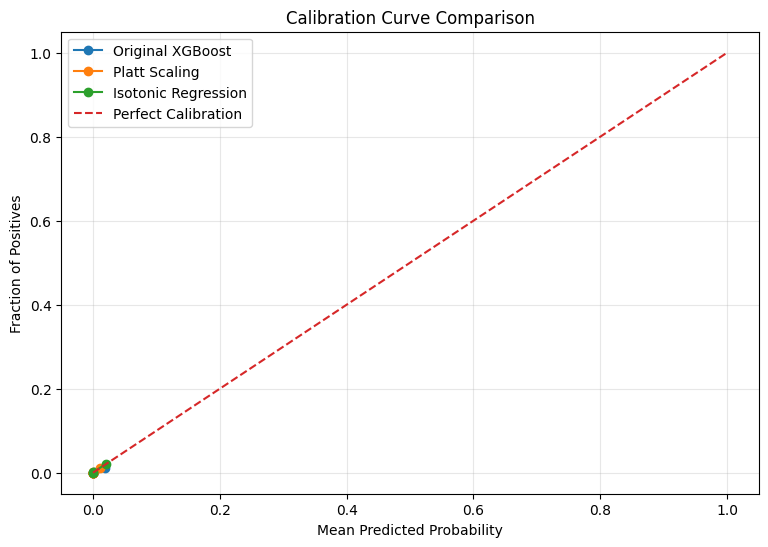

In [68]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

models = {
    "Original XGBoost": xgb_time_test_proba,
    "Platt Scaling": platt_time_test_proba,
    "Isotonic Regression": isotonic_time_test_proba
}

plt.figure(figsize=(9, 6))

for name, probabilities in models.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_test_time,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [69]:
print("Original ECE:", original_ece)
print("Platt ECE:", platt_ece)
print("Isotonic ECE:", isotonic_ece)

Original ECE: 0.0009896321145415542
Platt ECE: 0.0001806367240489265
Isotonic ECE: 0.00012160210399617328


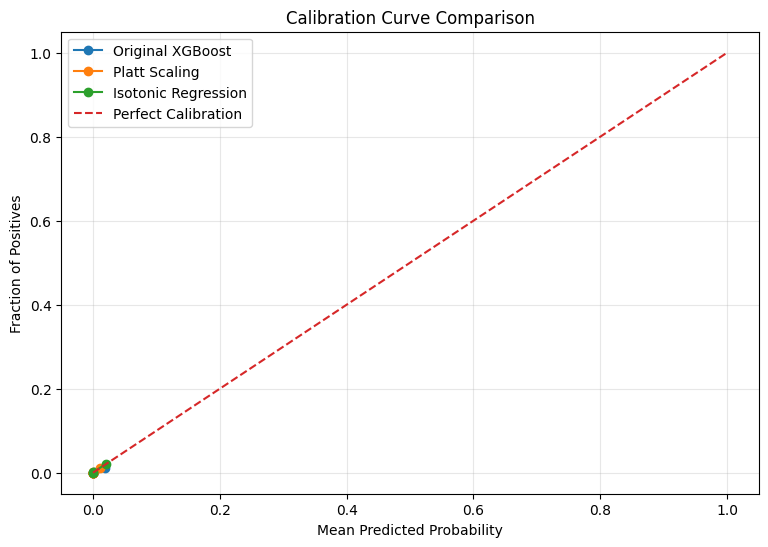

In [70]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

models = {
    "Original XGBoost": xgb_time_test_proba,
    "Platt Scaling": platt_time_test_proba,
    "Isotonic Regression": isotonic_time_test_proba
}

plt.figure(figsize=(9, 6))

for name, probabilities in models.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_test_time,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot([0, 1], [0, 1], "--", label="Perfect Calibration")

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [71]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Validation indekslərini ayırırıq
val_indices = np.arange(len(y_val_time))

cal_idx, threshold_idx = train_test_split(
    val_indices,
    test_size=0.5,
    random_state=42,
    stratify=y_val_time
)

# Hissələr
y_cal = y_val_time.iloc[cal_idx]
y_threshold = y_val_time.iloc[threshold_idx]

proba_cal = xgb_time_val_proba[cal_idx]
proba_threshold = xgb_time_val_proba[threshold_idx]

# 2. Isotonic Regression
isotonic_threshold_model = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

isotonic_threshold_model.fit(
    proba_cal,
    y_cal
)

isotonic_val_calibrated = isotonic_threshold_model.predict(
    proba_threshold
)

# 3. Platt Scaling
eps = 1e-7

cal_logits = np.log(
    np.clip(proba_cal, eps, 1-eps) /
    (1 - np.clip(proba_cal, eps, 1-eps))
).reshape(-1, 1)

threshold_logits = np.log(
    np.clip(proba_threshold, eps, 1-eps) /
    (1 - np.clip(proba_threshold, eps, 1-eps))
).reshape(-1, 1)

platt_threshold_model = LogisticRegression()

platt_threshold_model.fit(
    cal_logits,
    y_cal
)

platt_val_calibrated = (
    platt_threshold_model.predict_proba(threshold_logits)[:, 1]
)

print("Calibration set fraud:", y_cal.sum())
print("Threshold validation fraud:", y_threshold.sum())

Calibration set fraud: 28
Threshold validation fraud: 29


In [72]:
def threshold_analysis(y_true, probabilities, model_name):

    thresholds = np.unique(
        np.quantile(probabilities, np.linspace(0, 1, 101))
    )

    results = []

    for threshold in thresholds:
        y_pred = (probabilities >= threshold).astype(int)

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1-Score": f1_score(
                y_true, y_pred, zero_division=0
            )
        })

    return pd.DataFrame(results)


isotonic_threshold_results = threshold_analysis(
    y_threshold,
    isotonic_val_calibrated,
    "Isotonic"
)

platt_threshold_results = threshold_analysis(
    y_threshold,
    platt_val_calibrated,
    "Platt"
)

calibrated_threshold_results = pd.concat(
    [
        isotonic_threshold_results,
        platt_threshold_results
    ],
    ignore_index=True
)

best_calibrated_thresholds = (
    calibrated_threshold_results
    .sort_values("F1-Score", ascending=False)
    .groupby("Model")
    .head(1)
)

print(best_calibrated_thresholds.to_string(index=False))

   Model  Threshold  Precision   Recall  F1-Score
Isotonic   1.000000   1.000000 0.517241  0.681818
   Platt   0.003477   0.088028 0.862069  0.159744


In [73]:
from sklearn.metrics import confusion_matrix, classification_report

# Isotonic
iso_best_threshold = 1.0

iso_pred = (
    isotonic_val_calibrated >= iso_best_threshold
).astype(int)

print("ISOTONIC")
print(confusion_matrix(y_threshold, iso_pred))
print(classification_report(y_threshold, iso_pred))

# Platt
platt_best_threshold = 0.003477

platt_pred = (
    platt_val_calibrated >= platt_best_threshold
).astype(int)

print("\nPLATT")
print(confusion_matrix(y_threshold, platt_pred))
print(classification_report(y_threshold, platt_pred))

ISOTONIC
[[28344     0]
 [   14    15]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     28344
           1       1.00      0.52      0.68        29

    accuracy                           1.00     28373
   macro avg       1.00      0.76      0.84     28373
weighted avg       1.00      1.00      1.00     28373


PLATT
[[28085   259]
 [    4    25]]
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     28344
           1       0.09      0.86      0.16        29

    accuracy                           0.99     28373
   macro avg       0.54      0.93      0.58     28373
weighted avg       1.00      0.99      0.99     28373



In [74]:
print("Isotonic unique probabilities:",
      len(np.unique(isotonic_val_calibrated)))

print("\nIsotonic probability quantiles:")
print(pd.Series(isotonic_val_calibrated).describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
))

print("\nPlatt probability quantiles:")
print(pd.Series(platt_val_calibrated).describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
))

Isotonic unique probabilities: 34

Isotonic probability quantiles:
count    28373.000000
mean         0.001219
std          0.029518
min          0.000000
50%          0.000000
90%          0.000484
95%          0.001167
99%          0.001167
max          1.000000
dtype: float64

Platt probability quantiles:
count    28373.000000
mean         0.001237
std          0.029318
min          0.000010
50%          0.000085
90%          0.000484
95%          0.000912
99%          0.003477
max          0.995766
dtype: float64


In [75]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

test_models = {
    "Original XGBoost": (
        xgb_time_test_proba, 0.85
    ),
    "Isotonic": (
        isotonic_time_test_proba, 1.0
    ),
    "Platt": (
        platt_time_test_proba, 0.003477
    )
}

comparison = []

for name, (proba, threshold) in test_models.items():

    pred = (proba >= threshold).astype(int)

    comparison.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_test_time, pred),
        "Recall": recall_score(y_test_time, pred),
        "F1-Score": f1_score(y_test_time, pred),
        "False Positives": confusion_matrix(
            y_test_time, pred
        )[0, 1],
        "False Negatives": confusion_matrix(
            y_test_time, pred
        )[1, 0]
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

           Model  Threshold  Precision  Recall  F1-Score  False Positives  False Negatives
Original XGBoost     0.8500     0.8871  0.7432    0.8088                7               19
        Isotonic     1.0000     1.0000  0.5000    0.6667                0               37
           Platt     0.0035     0.1808  0.8378    0.2974              281               12


In [76]:
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50,
              0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:
    y_pred = (xgb_time_test_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_time, y_pred
    ).ravel()

    results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "Precision": precision_score(y_test_time, y_pred, zero_division=0),
        "Recall": recall_score(y_test_time, y_pred, zero_division=0),
        "F1": f1_score(y_test_time, y_pred, zero_division=0),
        "Fraud Detection Rate": tp / (tp + fn),
        "Flagged Transactions": tp + fp
    })

business_impact_df = pd.DataFrame(results)

print(business_impact_df.round(4).to_string(index=False))

 Threshold  TP  FP    TN  FN  Precision  Recall     F1  Fraud Detection Rate  Flagged Transactions
      0.10  58  60 56612  16     0.4915  0.7838 0.6042                0.7838                   118
      0.20  56  33 56639  18     0.6292  0.7568 0.6871                0.7568                    89
      0.30  56  19 56653  18     0.7467  0.7568 0.7517                0.7568                    75
      0.40  56  12 56660  18     0.8235  0.7568 0.7887                0.7568                    68
      0.50  56  12 56660  18     0.8235  0.7568 0.7887                0.7568                    68
      0.60  56   9 56663  18     0.8615  0.7568 0.8058                0.7568                    65
      0.70  56   8 56664  18     0.8750  0.7568 0.8116                0.7568                    64
      0.80  56   8 56664  18     0.8750  0.7568 0.8116                0.7568                    64
      0.85  55   7 56665  19     0.8871  0.7432 0.8088                0.7432                    62
      0.90

In [77]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Validation məlumatları
thresholds = np.arange(0.05, 1.00, 0.01)

# Müxtəlif biznes ssenariləri
cost_ratios = [5, 10, 20]

business_results = []

for ratio in cost_ratios:

    best_result = None
    min_cost = float("inf")

    for threshold in thresholds:

        y_pred = (xgb_time_val_proba >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_time, y_pred, labels=[0, 1]
        ).ravel()

        total_cost = fp + ratio * fn

        if total_cost < min_cost:
            min_cost = total_cost

            best_result = {
                "FN Cost Ratio": ratio,
                "Best Threshold": threshold,
                "TP": tp,
                "FP": fp,
                "FN": fn,
                "TN": tn,
                "Precision": tp / (tp + fp) if tp + fp > 0 else 0,
                "Recall": tp / (tp + fn) if tp + fn > 0 else 0,
                "F1": (
                    2 * tp / (2 * tp + fp + fn)
                    if (2 * tp + fp + fn) > 0 else 0
                ),
                "Total Cost": total_cost
            }

    business_results.append(best_result)

business_df = pd.DataFrame(business_results)

print(business_df.round(4).to_string(index=False))

 FN Cost Ratio  Best Threshold  TP  FP  FN    TN  Precision  Recall     F1  Total Cost
             5            0.81  43   4  14 56684     0.9149  0.7544 0.8269          74
            10            0.44  44  14  13 56674     0.7586  0.7719 0.7652         144
            20            0.18  46  45  11 56643     0.5055  0.8070 0.6216         265


In [78]:
selected_thresholds = {
    "5x Scenario": 0.81,
    "10x Scenario": 0.44,
    "20x Scenario": 0.18
}

final_results = []

for scenario, threshold in selected_thresholds.items():

    y_pred = (xgb_time_test_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_time, y_pred, labels=[0, 1]
    ).ravel()

    final_results.append({
        "Scenario": scenario,
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision_score(y_test_time, y_pred, zero_division=0),
        "Recall": recall_score(y_test_time, y_pred, zero_division=0),
        "F1": f1_score(y_test_time, y_pred, zero_division=0),
        "Total Cost": fp + int(scenario.split("x")[0]) * fn
    })

final_business_df = pd.DataFrame(final_results)

print(final_business_df.round(4).to_string(index=False))

    Scenario  Threshold  TP  FP  FN    TN  Precision  Recall     F1  Total Cost
 5x Scenario       0.81  56   8  18 56664     0.8750  0.7568 0.8116          98
10x Scenario       0.44  56  12  18 56660     0.8235  0.7568 0.7887         192
20x Scenario       0.18  56  36  18 56636     0.6087  0.7568 0.6747         396


In [79]:
import joblib
import os

# Model və threshold məlumatlarını bir yerdə saxlayaq
model_artifact = {
    "model": xgb_time_model,
    "threshold": 0.81,
    "features": X_train_time.columns.tolist()
}

# Modeli yadda saxla
joblib.dump(model_artifact, "fraud_detection_model.pkl")

print("Model successfully saved!")

Model successfully saved!


In [80]:
loaded_artifact = joblib.load("fraud_detection_model.pkl")

loaded_model = loaded_artifact["model"]
threshold = loaded_artifact["threshold"]
feature_columns = loaded_artifact["features"]

print("Model loaded successfully!")
print("Threshold:", threshold)
print("Number of features:", len(feature_columns))

Model loaded successfully!
Threshold: 0.81
Number of features: 30


In [83]:
import pandas as pd

def predict_fraud(transaction):

    # Input-u DataFrame-ə çeviririk
    transaction_df = pd.DataFrame([transaction])

    # Feature sırasını modelə uyğunlaşdırırıq
    transaction_df = transaction_df[feature_columns]

    # Fraud ehtimalını hesablayırıq
    fraud_probability = loaded_model.predict_proba(
        transaction_df
    )[0][1]

    # Threshold əsasında qərar
    prediction = (
        "Potential Fraud"
        if fraud_probability >= threshold
        else "Normal"
    )

    return {
        "Fraud Probability": round(float(fraud_probability), 4),
        "Prediction": prediction,
        "Threshold": threshold
    }

In [84]:

sample_transaction = X_test_time.iloc[0].to_dict()

# Prediction
result = predict_fraud(sample_transaction)

print(result)

{'Fraud Probability': 0.0004, 'Prediction': 'Normal', 'Threshold': 0.81}


In [85]:
actual_class = y_test_time.iloc[0]

print("Actual Class:", actual_class)
print("Prediction Result:", result)

Actual Class: 0
Prediction Result: {'Fraud Probability': 0.0004, 'Prediction': 'Normal', 'Threshold': 0.81}


In [86]:
def predict_fraud_batch(transactions):

    # Feature-ları modelin gözlədiyi sıraya salırıq
    transactions = transactions[feature_columns].copy()

    # Hər əməliyyat üçün fraud ehtimalı
    probabilities = loaded_model.predict_proba(transactions)[:, 1]

    # Threshold əsasında proqnoz
    predictions = (probabilities >= threshold).astype(int)

    # Nəticə cədvəli
    results = pd.DataFrame({
        "Fraud Probability": probabilities,
        "Prediction": [
            "Potential Fraud" if p == 1 else "Normal"
            for p in predictions
        ]
    })

    return results

In [87]:
sample_transactions = X_test_time.iloc[:10]

batch_results = predict_fraud_batch(sample_transactions)

batch_results["Actual Class"] = (
    y_test_time.iloc[:10].values
)

batch_results["Actual Label"] = (
    batch_results["Actual Class"]
    .map({0: "Normal", 1: "Fraud"})
)

print(batch_results.round(4).to_string())

   Fraud Probability Prediction  Actual Class Actual Label
0             0.0004     Normal             0       Normal
1             0.0002     Normal             0       Normal
2             0.0007     Normal             0       Normal
3             0.0027     Normal             0       Normal
4             0.0002     Normal             0       Normal
5             0.0017     Normal             0       Normal
6             0.0128     Normal             0       Normal
7             0.0000     Normal             0       Normal
8             0.0003     Normal             0       Normal
9             0.0001     Normal             0       Normal


In [88]:

fraud_indices = y_test_time[y_test_time == 1].index[:10]

fraud_transactions = X_test_time.loc[fraud_indices]

# Prediction
fraud_results = predict_fraud_batch(fraud_transactions)

# Həqiqi nəticələri əlavə edirik
fraud_results["Actual Class"] = 1
fraud_results["Actual Label"] = "Fraud"

print(fraud_results.round(4).to_string())

   Fraud Probability       Prediction  Actual Class Actual Label
0             0.9993  Potential Fraud             1        Fraud
1             0.1608           Normal             1        Fraud
2             0.9984  Potential Fraud             1        Fraud
3             0.9981  Potential Fraud             1        Fraud
4             0.0186           Normal             1        Fraud
5             0.8285  Potential Fraud             1        Fraud
6             0.9994  Potential Fraud             1        Fraud
7             0.9873  Potential Fraud             1        Fraud
8             0.9836  Potential Fraud             1        Fraud
9             0.9992  Potential Fraud             1        Fraud


In [89]:

all_test_results = predict_fraud_batch(X_test_time)

y_pred_all = (
    xgb_time_test_proba >= threshold
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test_time, y_pred_all))

print("\nClassification Report:")
print(classification_report(
    y_test_time,
    y_pred_all,
    target_names=["Normal", "Fraud"]
))

Confusion Matrix:
[[56664     8]
 [   18    56]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56672
       Fraud       0.88      0.76      0.81        74

    accuracy                           1.00     56746
   macro avg       0.94      0.88      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [90]:
!pip install fastapi uvicorn -q

In [91]:
%%writefile app.py

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import Dict
import pandas as pd
import joblib

# Modeli yükləyirik
artifact = joblib.load("fraud_detection_model.pkl")

model = artifact["model"]
threshold = artifact["threshold"]
feature_columns = artifact["features"]

app = FastAPI(
    title="Bank Fraud Detection API",
    description="XGBoost-based Fraud Detection System",
    version="1.0"
)


class Transaction(BaseModel):
    features: Dict[str, float]


@app.get("/")
def home():
    return {
        "message": "Fraud Detection API is running",
        "threshold": threshold
    }


@app.post("/predict")
def predict(transaction: Transaction):

    try:
        input_data = transaction.features

        # Çatışmayan feature-ları yoxlayırıq
        missing_features = [
            col for col in feature_columns
            if col not in input_data
        ]

        if missing_features:
            raise HTTPException(
                status_code=400,
                detail=f"Missing features: {missing_features}"
            )

        # Model üçün DataFrame hazırlayırıq
        df = pd.DataFrame(
            [[input_data[col] for col in feature_columns]],
            columns=feature_columns
        )

        # Fraud probability
        probability = float(
            model.predict_proba(df)[0][1]
        )

        # Classification
        prediction = (
            "Potential Fraud"
            if probability >= threshold
            else "Normal"
        )

        return {
            "fraud_probability": round(probability, 6),
            "prediction": prediction,
            "threshold": threshold
        }

    except HTTPException:
        raise

    except Exception as e:
        raise HTTPException(
            status_code=500,
            detail=str(e)
        )

Writing app.py


In [92]:
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

response = client.get("/")

print(response.status_code)
print(response.json())

200
{'message': 'Fraud Detection API is running', 'threshold': 0.81}


In [93]:
sample_transaction = X_test_time.iloc[0].to_dict()

response = client.post(
    "/predict",
    json={"features": sample_transaction}
)

print("Status Code:", response.status_code)
print("API Response:", response.json())

Status Code: 200
API Response: {'fraud_probability': 0.000366, 'prediction': 'Normal', 'threshold': 0.81}


In [94]:

fraud_index = y_test_time[y_test_time == 1].index[0]

fraud_transaction = X_test_time.loc[fraud_index].to_dict()

response = client.post(
    "/predict",
    json={"features": fraud_transaction}
)

print("Status Code:", response.status_code)
print("API Response:", response.json())

Status Code: 200
API Response: {'fraud_probability': 0.999341, 'prediction': 'Potential Fraud', 'threshold': 0.81}


In [95]:
incomplete_transaction = {
    "V1": 0.5,
    "V2": -1.2
}

response = client.post(
    "/predict",
    json={"features": incomplete_transaction}
)

print("Status Code:", response.status_code)
print("API Response:", response.json())

Status Code: 400
API Response: {'detail': "Missing features: ['Time', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']"}


In [96]:
fraud_index = y_test_time[y_test_time == 1].index[0]

fraud_transaction = X_test_time.loc[fraud_index].to_dict()

response = client.post(
    "/predict",
    json={"features": fraud_transaction}
)

print("Status Code:", response.status_code)
print("API Response:", response.json())

Status Code: 200
API Response: {'fraud_probability': 0.999341, 'prediction': 'Potential Fraud', 'threshold': 0.81}


In [97]:
print("Swagger UI endpoint: /docs")

Swagger UI endpoint: /docs


In [98]:
response = client.get("/openapi.json")

print("Status Code:", response.status_code)
print("Available Endpoints:", list(response.json()["paths"].keys()))

Status Code: 200
Available Endpoints: ['/', '/predict']


In [100]:
requirements = """
pandas
numpy
scikit-learn
xgboost
joblib
fastapi
uvicorn
pydantic
"""

with open("requirements.txt", "w") as f:
    f.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [101]:
import os

print(os.listdir())

['.config', '__pycache__', 'creditcard.csv', 'app.py', 'fraud_detection_model.pkl', 'requirements.txt', 'sample_data']


In [102]:
readme = """
# Bank Fraud Detection System

## Project Overview
This project focuses on detecting fraudulent credit card transactions
using machine learning techniques.

The main objective is to identify potentially fraudulent transactions
while balancing precision and recall.

## Dataset
Credit Card Fraud Detection Dataset from Kaggle.

The dataset contains anonymized transaction features (V1-V28),
Time, Amount, and the target variable Class.

## Methodology
- Data Cleaning and Exploratory Data Analysis
- Handling Class Imbalance
- Logistic Regression
- Random Forest
- XGBoost
- Time-based Train/Validation/Test Split
- Threshold Optimization
- Model Evaluation
- SHAP-based Model Interpretation
- Probability Calibration

## Best Model
XGBoost Classifier

## Evaluation
The final model was evaluated using a time-based split.

Selected decision threshold: 0.81

Test results:
- Precision: 0.875
- Recall: 0.757
- F1-score: 0.812

Confusion Matrix:
- True Negatives: 56664
- False Positives: 8
- False Negatives: 18
- True Positives: 56

## API
A REST API was developed using FastAPI.

Available endpoints:
- GET /
- POST /predict

Interactive API documentation is available through /docs.

## Technologies
Python, Pandas, NumPy, Scikit-learn, XGBoost,
SHAP, FastAPI, Joblib.

## Disclaimer
This project is developed for educational and portfolio purposes.
The model has not been validated for real-world banking deployment.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme.strip())

print("README.md created successfully!")

README.md created successfully!


In [103]:
import os

print(os.listdir())

['.config', '__pycache__', 'creditcard.csv', 'app.py', 'README.md', 'fraud_detection_model.pkl', 'requirements.txt', 'sample_data']
